# BUSA3022 — Part 1: Data Pipeline Proof of Concept

Sources: Yahoo Finance S&P 500 (`^GSPC`) and FRED VIX (`VIXCLS`). This notebook preserves raw observations before validation. Live fetching requires internet and is **not verified by the local tests**. All timestamps for ingestion are UTC; dates are retained as provider observation dates. No cross-series alignment occurs here; Member 2 owns it.

In [1]:
!unzip -o -q /content/BUSA3022_Part1_Starter_Package.zip -d /content/

unzip:  cannot find or open /content/BUSA3022_Part1_Starter_Package.zip, /content/BUSA3022_Part1_Starter_Package.zip.zip or /content/BUSA3022_Part1_Starter_Package.zip.ZIP.


In [2]:
import os

print("Current folder:", os.getcwd())
print("\nFiles and folders:")
for item in os.listdir("/content"):
    print(" -", item)

Current folder: /content

Files and folders:
 - .config
 - BUSA3022_Part1_Starter_Package (1).zip
 - sample_data


In [4]:
import zipfile
import os

zip_path = "/content/BUSA3022_Part1_Starter_Package (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside the ZIP:")
    for name in z.namelist()[:30]:
        print(name)

    z.extractall("/content")

print("\nExtraction completed successfully!")
print("\nFiles in /content:")
print(os.listdir("/content"))

Files inside the ZIP:
busa3022_part1/requirements.txt
busa3022_part1/README.md
busa3022_part1/tests/__init__.py
busa3022_part1/tests/test_pipeline.py
busa3022_part1/docs/pipeline_design.md
busa3022_part1/docs/architecture.mmd
busa3022_part1/docs/handover_member2.md
busa3022_part1/src/pipeline.py
busa3022_part1/notebooks/01_data_pipeline.ipynb
busa3022_part1/src/__pycache__/pipeline.cpython-313.pyc

Extraction completed successfully!

Files in /content:
['.config', 'BUSA3022_Part1_Starter_Package (1).zip', 'busa3022_part1', 'sample_data']


In [5]:
%cd /content/busa3022_part1

/content/busa3022_part1


In [6]:
!pip -q install -r requirements.txt

If using Colab, upload the project folder or clone the shared GitHub repository and change the working directory to its root before running the following cells.

In [7]:
from pathlib import Path
from src.pipeline import run_live
results = run_live(Path.cwd(), days=180)
print(results)

{'market': {'raw_rows': 124, 'accepted': 124, 'quarantined': 0}, 'macro': {'raw_rows': 127, 'accepted': 127, 'quarantined': 0}}


The next cell runs deterministic local failure tests; the input is **synthetic**, not evidence of real market-data defects.

In [8]:
from tests.test_pipeline import run
run()

PASS: raw preserved; missing value, duplicate dates, bad date and schema change detected; logs created


In [9]:
from pathlib import Path

project = Path("/content/busa3022_part1")

print("FILES CREATED BY OUR PIPELINE:\n")

for folder in ["data", "logs"]:
    folder_path = project / folder

    if folder_path.exists():
        for file in sorted(folder_path.rglob("*")):
            if file.is_file():
                print(file.relative_to(project))
    else:
        print(f"{folder} folder not found")

FILES CREATED BY OUR PIPELINE:

data/raw/macro/macro_20261029T083237Z_97d5e3.csv
data/raw/market/market_20261029T083237Z_97d5e3.csv
data/validated/macro_validated.csv
data/validated/market_validated.csv
logs/data_quality_log.csv


In [10]:
import pandas as pd

market = pd.read_csv(
    "/content/busa3022_part1/data/validated/market_validated.csv"
)

macro = pd.read_csv(
    "/content/busa3022_part1/data/validated/macro_validated.csv"
)

print("S&P 500 MARKET DATA:")
print(market.head())

print("\nVIX MACRO DATA:")
print(macro.head())

print("\nMARKET COLUMNS:", market.columns.tolist())
print("MACRO COLUMNS:", macro.columns.tolist())

S&P 500 MARKET DATA:
         date    adj_close        close         high          low  \
0  2026-05-04  7200.750000  7200.750000  7244.540039  7174.120117   
1  2026-05-05  7259.220215  7259.220215  7273.259766  7233.620117   
2  2026-05-06  7365.120117  7365.120117  7369.220215  7294.140137   
3  2026-05-07  7337.109863  7337.109863  7385.020020  7321.250000   
4  2026-05-08  7398.930176  7398.930176  7401.500000  7362.970215   

          open      volume  
0  7228.379883  5215480000  
1  7233.620117  5279760000  
2  7294.140137  6579640000  
3  7376.779785  6237040000  
4  7362.970215  5302740000  

VIX MACRO DATA:
         date    vix
0  2026-05-04  18.29
1  2026-05-05  17.38
2  2026-05-06  17.39
3  2026-05-07  17.08
4  2026-05-08  17.19

MARKET COLUMNS: ['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume']
MACRO COLUMNS: ['date', 'vix']


In [11]:
import pandas as pd

log = pd.read_csv(
    "/content/busa3022_part1/logs/data_quality_log.csv"
)

print("DATA QUALITY LOG:")
print(log.to_string(index=False))

print("\nTOTAL LOG ENTRIES:", len(log))
print("\nLOG COLUMNS:", log.columns.tolist())

DATA QUALITY LOG:
                       event_utc                  run_id source               issue  affected_rows                                             detail
2026-10-29T08:32:39.341544+00:00 20261029T083237Z_97d5e3 market        RAW_CAPTURED            124 data/raw/market/market_20261029T083237Z_97d5e3.csv
2026-10-29T08:32:39.356916+00:00 20261029T083237Z_97d5e3 market VALIDATION_COMPLETE              0                        124 accepted, 0 quarantined
2026-10-29T08:32:39.577289+00:00 20261029T083237Z_97d5e3  macro        RAW_CAPTURED            127   data/raw/macro/macro_20261029T083237Z_97d5e3.csv
2026-10-29T08:32:39.584328+00:00 20261029T083237Z_97d5e3  macro VALIDATION_COMPLETE              0                        127 accepted, 0 quarantined

TOTAL LOG ENTRIES: 4

LOG COLUMNS: ['event_utc', 'run_id', 'source', 'issue', 'affected_rows', 'detail']


In [12]:
import shutil

shutil.make_archive(
    "/content/BUSA3022_Part1_Working_Backup",
    "zip",
    root_dir="/content",
    base_dir="busa3022_part1"
)

print("Backup created successfully!")
print("/content/BUSA3022_Part1_Working_Backup.zip")

Backup created successfully!
/content/BUSA3022_Part1_Working_Backup.zip


In [13]:
import pandas as pd

market = pd.read_csv(
    "/content/busa3022_part1/data/validated/market_validated.csv"
)

macro = pd.read_csv(
    "/content/busa3022_part1/data/validated/macro_validated.csv"
)

print("S&P 500 MARKET DATA")
print("Number of records:", len(market))
print("First date:", market["date"].min())
print("Last date:", market["date"].max())
print("Missing values:")
print(market.isna().sum())

print("\nVIX MACRO DATA")
print("Number of records:", len(macro))
print("First date:", macro["date"].min())
print("Last date:", macro["date"].max())
print("Missing values:")
print(macro.isna().sum())

print("\nLATEST MARKET RECORDS:")
print(market.tail(3).to_string(index=False))

print("\nLATEST VIX RECORDS:")
print(macro.tail(3).to_string(index=False))

S&P 500 MARKET DATA
Number of records: 124
First date: 2026-05-04
Last date: 2026-10-28
Missing values:
date         0
adj_close    0
close        0
high         0
low          0
open         0
volume       0
dtype: int64

VIX MACRO DATA
Number of records: 127
First date: 2026-05-04
Last date: 2026-10-27
Missing values:
date    0
vix     0
dtype: int64

LATEST MARKET RECORDS:
      date   adj_close       close        high         low        open     volume
2026-10-26 7676.770020 7676.770020 7702.129883 7639.700195 7639.700195 5838070000
2026-10-27 7722.600098 7722.600098 7736.240234 7677.160156 7699.470215 5160120000
2026-10-28 7743.979980 7743.979980 7758.430176 7718.370117 7735.560059 5466960000

LATEST VIX RECORDS:
      date   vix
2026-10-23 19.45
2026-10-26 18.39
2026-10-27 17.52


In [14]:
from pathlib import Path

pipeline_file = Path(
    "/content/busa3022_part1/src/pipeline.py"
)

print(pipeline_file.read_text(encoding="utf-8"))

"""BUSA3022 Part 1: demonstrator ingestion, preservation and validation.
Live fetch requires internet and installs specified in requirements.txt.
"""
from pathlib import Path
from datetime import datetime, timezone, timedelta
import csv
import io
import json
import uuid
import pandas as pd
import requests

MARKET_REQUIRED = ['date','open','high','low','close']
MACRO_REQUIRED = ['date','vix']

def quality_log(root, source, issue, count=0, detail='', run_id='manual'):
    path=Path(root)/'logs'/'data_quality_log.csv'; path.parent.mkdir(parents=True,exist_ok=True)
    record={'event_utc':datetime.now(timezone.utc).isoformat(),'run_id':run_id,'source':source,'issue':issue,'affected_rows':int(count),'detail':str(detail)}
    with path.open('a',newline='',encoding='utf-8') as f:
        w=csv.DictWriter(f,fieldnames=list(record));
        if f.tell()==0:w.writeheader()
        w.writerow(record)
    return record

def validate(df, kind, root, run_id='manual'):
    """Validate only. No dates 

In [15]:
import pandas as pd
import requests
from io import StringIO

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=VIXCLS"

response = requests.get(url, timeout=25)
response.raise_for_status()

fred = pd.read_csv(StringIO(response.text))
fred.columns = [c.lower() for c in fred.columns]

if "observation_date" in fred.columns:
    fred = fred.rename(columns={"observation_date": "date"})

if "vixcls" in fred.columns:
    fred = fred.rename(columns={"vixcls": "vix"})

saved = pd.read_csv(
    "/content/busa3022_part1/data/validated/macro_validated.csv"
)

fred["date"] = pd.to_datetime(fred["date"])
saved["date"] = pd.to_datetime(saved["date"])

comparison = saved.merge(
    fred[["date", "vix"]],
    on="date",
    how="left",
    suffixes=("_saved", "_fred")
)

comparison["difference"] = (
    pd.to_numeric(comparison["vix_saved"], errors="coerce")
    - pd.to_numeric(comparison["vix_fred"], errors="coerce")
).abs()

print("RECORDS COMPARED:", len(comparison))
print("MATCHING VALUES:", (comparison["difference"] < 0.0001).sum())
print("DIFFERENT VALUES:", (comparison["difference"] >= 0.0001).sum())
print("DATES NOT FOUND IN FRED:", comparison["vix_fred"].isna().sum())

print("\nLATEST COMPARISON:")
print(comparison.tail(5).to_string(index=False))

RECORDS COMPARED: 127
MATCHING VALUES: 127
DIFFERENT VALUES: 0
DATES NOT FOUND IN FRED: 0

LATEST COMPARISON:
      date  vix_saved  vix_fred  difference
2026-10-21      16.68     16.68         0.0
2026-10-22      19.03     19.03         0.0
2026-10-23      19.45     19.45         0.0
2026-10-26      18.39     18.39         0.0
2026-10-27      17.52     17.52         0.0


In [16]:
import pandas as pd
import yfinance as yf

saved_market = pd.read_csv(
    "/content/busa3022_part1/data/validated/market_validated.csv"
)

start_date = saved_market["date"].min()
end_date = (
    pd.to_datetime(saved_market["date"].max())
    + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

fresh_market = yf.download(
    "^GSPC",
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False,
    threads=False
)

if isinstance(fresh_market.columns, pd.MultiIndex):
    fresh_market.columns = fresh_market.columns.get_level_values(0)

fresh_market = fresh_market.reset_index()
fresh_market.columns = [str(c).lower() for c in fresh_market.columns]

comparison = saved_market[["date", "close"]].merge(
    fresh_market[["date", "close"]],
    on="date",
    how="left",
    suffixes=("_saved", "_fresh")
)

comparison["difference"] = (
    comparison["close_saved"] - comparison["close_fresh"]
).abs()

print("RECORDS COMPARED:", len(comparison))
print("MATCHING VALUES:", (comparison["difference"] < 0.01).sum())
print("DIFFERENT VALUES:", (comparison["difference"] >= 0.01).sum())
print("DATES NOT FOUND:", comparison["close_fresh"].isna().sum())

print("\nLATEST COMPARISON:")
print(comparison.tail(5).to_string(index=False))

ValueError: You are trying to merge on object and datetime64[ns] columns for key 'date'. If you wish to proceed you should use pd.concat

In [17]:
import pandas as pd
import yfinance as yf

# Read our previously saved market data
saved_market = pd.read_csv(
    "/content/busa3022_part1/data/validated/market_validated.csv"
)

# Convert saved dates into a proper date format
saved_market["date"] = pd.to_datetime(saved_market["date"]).dt.normalize()

# Determine the period for the comparison
start_date = saved_market["date"].min().strftime("%Y-%m-%d")
end_date = (
    saved_market["date"].max() + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

# Download S&P 500 data again
fresh_market = yf.download(
    "^GSPC",
    start=start_date,
    end=end_date,
    auto_adjust=False,
    progress=False,
    threads=False
)

# Handle Yahoo Finance's column format
if isinstance(fresh_market.columns, pd.MultiIndex):
    fresh_market.columns = fresh_market.columns.get_level_values(0)

fresh_market = fresh_market.reset_index()
fresh_market.columns = [str(c).lower() for c in fresh_market.columns]

# Convert fresh dates into the same format
fresh_market["date"] = pd.to_datetime(
    fresh_market["date"]
).dt.normalize()

# Match the two datasets using their dates
comparison = saved_market[["date", "close"]].merge(
    fresh_market[["date", "close"]],
    on="date",
    how="left",
    suffixes=("_saved", "_fresh"),
    validate="one_to_one"
)

# Calculate the absolute price difference
comparison["difference"] = (
    comparison["close_saved"] - comparison["close_fresh"]
).abs()

print("RECORDS COMPARED:", len(comparison))
print("MATCHING VALUES:", (comparison["difference"] < 0.01).sum())
print("DIFFERENT VALUES:", (comparison["difference"] >= 0.01).sum())
print("DATES NOT FOUND:", comparison["close_fresh"].isna().sum())

print("\nLATEST COMPARISON:")
print(comparison.tail(5).to_string(index=False))

RECORDS COMPARED: 124
MATCHING VALUES: 124
DIFFERENT VALUES: 0
DATES NOT FOUND: 0

LATEST COMPARISON:
      date  close_saved  close_fresh  difference
2026-10-22  7663.430176  7663.430176         0.0
2026-10-23  7623.680176  7623.680176         0.0
2026-10-26  7676.770020  7676.770020         0.0
2026-10-27  7722.600098  7722.600098         0.0
2026-10-28  7743.979980  7743.979980         0.0


In [18]:
import pandas as pd
from pathlib import Path

project = Path("/content/busa3022_part1")

verification = pd.DataFrame([
    {
        "source": "Yahoo Finance",
        "series": "S&P 500 (^GSPC)",
        "records_compared": 124,
        "matching_values": 124,
        "different_values": 0,
        "dates_not_found": 0,
        "verification_method": "Repeat download comparison"
    },
    {
        "source": "FRED",
        "series": "VIX (VIXCLS)",
        "records_compared": 127,
        "matching_values": 127,
        "different_values": 0,
        "dates_not_found": 0,
        "verification_method": "Repeat download comparison"
    }
])

output = project / "docs" / "source_verification.csv"
output.parent.mkdir(parents=True, exist_ok=True)

verification.to_csv(output, index=False)

print("Verification evidence saved successfully!")
print("File:", output)
print(verification.to_string(index=False))

Verification evidence saved successfully!
File: /content/busa3022_part1/docs/source_verification.csv
       source          series  records_compared  matching_values  different_values  dates_not_found        verification_method
Yahoo Finance S&P 500 (^GSPC)               124              124                 0                0 Repeat download comparison
         FRED    VIX (VIXCLS)               127              127                 0                0 Repeat download comparison


In [19]:
import shutil
from pathlib import Path

backup_path = shutil.make_archive(
    "/content/BUSA3022_Part1_Verified_Backup",
    "zip",
    root_dir="/content",
    base_dir="busa3022_part1"
)

print("UPDATED BACKUP CREATED!")
print("Location:", backup_path)
print("File size:", round(Path(backup_path).stat().st_size / 1024, 1), "KB")

UPDATED BACKUP CREATED!
Location: /content/BUSA3022_Part1_Verified_Backup.zip
File size: 25.4 KB


In [20]:
from pathlib import Path

project = Path("/content/busa3022_part1")
diagram_folder = project / "diagrams"
diagram_folder.mkdir(parents=True, exist_ok=True)

diagram = """
flowchart TD
    A["Yahoo Finance: S&P 500"] --> C["Python ingestion"]
    B["FRED: VIX"] --> C
    C --> D["Raw CSV snapshots"]
    D --> E["Schema and data-quality validation"]
    E --> F["Validated CSV datasets"]
    E --> G["Quarantined records"]
    C --> H["Quality and execution logs"]
    E --> H
    F --> I["Member 2: Data curation and metrics"]
"""

output = diagram_folder / "pipeline_architecture.mmd"
output.write_text(diagram.strip(), encoding="utf-8")

print("ARCHITECTURE FILE CREATED!")
print("Location:", output)
print(output.read_text())

ARCHITECTURE FILE CREATED!
Location: /content/busa3022_part1/diagrams/pipeline_architecture.mmd
flowchart TD
    A["Yahoo Finance: S&P 500"] --> C["Python ingestion"]
    B["FRED: VIX"] --> C
    C --> D["Raw CSV snapshots"]
    D --> E["Schema and data-quality validation"]
    E --> F["Validated CSV datasets"]
    E --> G["Quarantined records"]
    C --> H["Quality and execution logs"]
    E --> H
    F --> I["Member 2: Data curation and metrics"]


In [21]:
from pathlib import Path
from IPython.display import Image, display
import subprocess

project = Path("/content/busa3022_part1")
source = project / "diagrams/pipeline_architecture.mmd"
output = project / "diagrams/pipeline_architecture.png"

# Install the Mermaid diagram converter
subprocess.run(
    ["npm", "install", "-g", "@mermaid-js/mermaid-cli"],
    check=True
)

# Convert the existing diagram into a PNG image
subprocess.run(
    [
        "mmdc",
        "-i", str(source),
        "-o", str(output),
        "-b", "white",
        "-w", "1600"
    ],
    check=True
)

print("ARCHITECTURE DIAGRAM CREATED SUCCESSFULLY!")
print("Saved at:", output)

display(Image(filename=str(output)))

CalledProcessError: Command '['mmdc', '-i', '/content/busa3022_part1/diagrams/pipeline_architecture.mmd', '-o', '/content/busa3022_part1/diagrams/pipeline_architecture.png', '-b', 'white', '-w', '1600']' returned non-zero exit status 1.

ARCHITECTURE DIAGRAM CREATED SUCCESSFULLY!
Saved at: /content/busa3022_part1/diagrams/pipeline_architecture.png


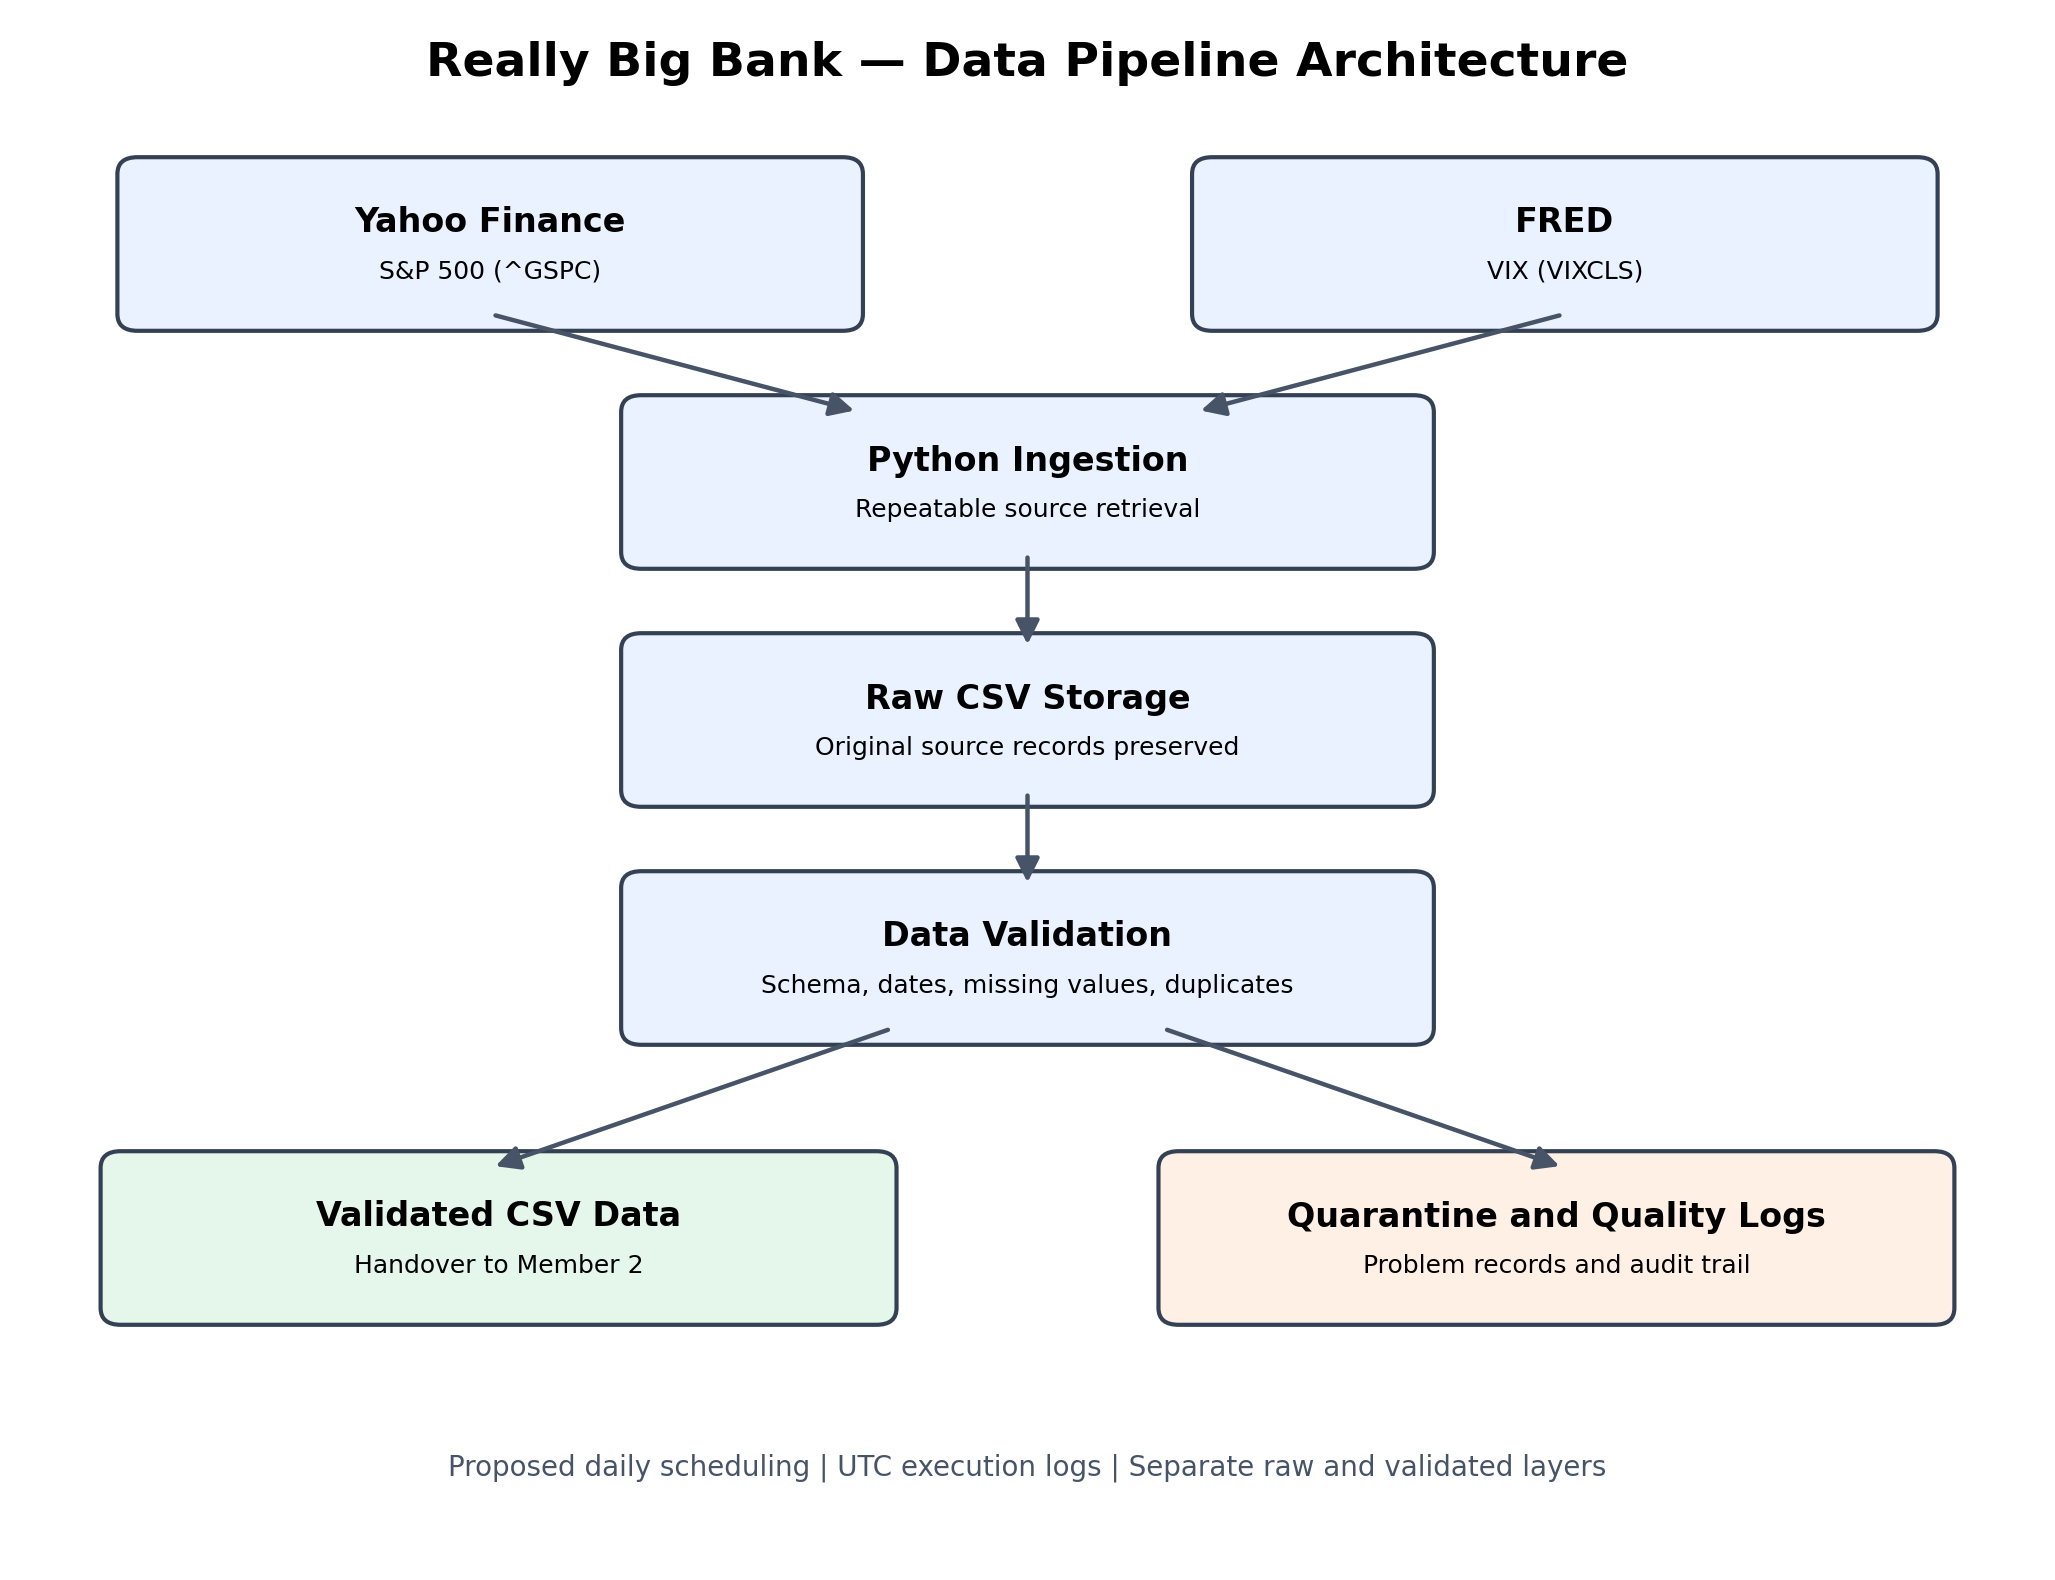

In [22]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, Image

project = Path("/content/busa3022_part1")
folder = project / "diagrams"
folder.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(13, 10))
ax.set_xlim(0, 12)
ax.set_ylim(0, 11)
ax.axis("off")

def box(x, y, w, h, title, subtitle="", color="#EAF2FF"):
    shape = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        facecolor=color,
        edgecolor="#344054",
        linewidth=1.5
    )
    ax.add_patch(shape)
    ax.text(x+w/2, y+h*0.65, title,
            ha="center", va="center",
            fontsize=12, fontweight="bold")
    if subtitle:
        ax.text(x+w/2, y+h*0.30, subtitle,
                ha="center", va="center", fontsize=9)

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=1.6,
        color="#475467"
    ))

ax.text(6, 10.6, "Really Big Bank — Data Pipeline Architecture",
        ha="center", fontsize=17, fontweight="bold")

box(0.7, 8.9, 4.2, 1, "Yahoo Finance", "S&P 500 (^GSPC)")
box(7.1, 8.9, 4.2, 1, "FRED", "VIX (VIXCLS)")

box(3.7, 7.2, 4.6, 1,
    "Python Ingestion", "Repeatable source retrieval")

box(3.7, 5.5, 4.6, 1,
    "Raw CSV Storage", "Original source records preserved")

box(3.7, 3.8, 4.6, 1,
    "Data Validation", "Schema, dates, missing values, duplicates")

box(0.6, 1.8, 4.5, 1,
    "Validated CSV Data", "Handover to Member 2", "#E5F6EA")

box(6.9, 1.8, 4.5, 1,
    "Quarantine and Quality Logs", "Problem records and audit trail",
    "#FFF0E5")

arrow(2.8, 8.9, 5.0, 8.2)
arrow(9.2, 8.9, 7.0, 8.2)
arrow(6, 7.2, 6, 6.5)
arrow(6, 5.5, 6, 4.8)
arrow(5.2, 3.8, 2.8, 2.8)
arrow(6.8, 3.8, 9.2, 2.8)

ax.text(6, 0.6,
        "Proposed daily scheduling | UTC execution logs | "
        "Separate raw and validated layers",
        ha="center", fontsize=10, color="#475467")

output = folder / "pipeline_architecture.png"

plt.savefig(output, dpi=200, bbox_inches="tight",
            facecolor="white")
plt.close(fig)

print("ARCHITECTURE DIAGRAM CREATED SUCCESSFULLY!")
print("Saved at:", output)

display(Image(filename=str(output)))

In [23]:
from pathlib import Path

document = Path(
    "/content/busa3022_part1/docs/pipeline_design.md"
)

print("CURRENT PIPELINE DESIGN DOCUMENT:\n")
print(document.read_text(encoding="utf-8"))

CURRENT PIPELINE DESIGN DOCUMENT:

# Pipeline design decisions (v1)

- **Business question:** how has market activity trended over 90 days?
- **Market source:** Yahoo Finance, `^GSPC`, daily OHLC prices. Volume is optional and not relied on for the core design.
- **Macro source:** FRED, `VIXCLS`, daily VIX closing observation. VIX is forward-looking implied volatility, not realised index volatility.
- **Ingestion window:** 180 calendar days to support initial rolling calculations and the display window.
- **Schedule proposal:** GitHub Actions daily, after US market close with a publication lag; use manual Colab execution as a demonstrator. Scheduling has not yet been deployed.
- **Stages:** provider fetch → immutable timestamped raw CSV → schema and row checks → validated CSV + quarantined rows and CSV quality log → Member 2 transformations.
- **Quality rules:** required fields, parseable date, positive OHLC, numeric values, duplicate observation dates. Source availability, trading hol

In [24]:
from pathlib import Path

document = Path(
    "/content/busa3022_part1/docs/pipeline_design.md"
)

additional_documentation = """

## Proof-of-concept execution evidence — 29 October 2026

### Live ingestion results
- Yahoo Finance S&P 500 (^GSPC): 124 rows retrieved, 124 accepted, 0 quarantined.
- FRED VIX (VIXCLS): 127 rows retrieved, 127 accepted, 0 quarantined.
- Total: 251 accepted observations.
- Historical period: 4 May 2026 onwards.
- Latest S&P 500 observation: 28 October 2026.
- Latest VIX observation: 27 October 2026.

### Data-quality logging
The live execution generated four log events:
- Market raw capture.
- Market validation completion.
- Macro raw capture.
- Macro validation completion.

Logs contain UTC timestamps, a run identifier, source,
event type, affected row count and descriptive details.

### Controlled failure testing
Synthetic test records were used to confirm detection of:
- Missing values.
- Duplicate observation dates.
- Invalid dates.
- Schema changes.

The tests also confirmed raw-data preservation and log creation.
These deliberately introduced errors are not claimed to have
occurred in the downloaded financial datasets.

### Source-verification evidence
Saved data was compared with fresh downloads from the same providers.

- S&P 500: 124 of 124 closing values matched within 0.01.
- VIX: 127 of 127 observations matched within 0.0001.
- No comparison dates were missing.
- Evidence file: docs/source_verification.csv.

These are repeat-download consistency checks, not independent
verification against a second financial-data provider.

### Known limitations
- Automated scheduling is proposed but has not been deployed.
- Missing values in future source updates may require investigation.
- Source publication lag explains why data freshness must be
  assessed against the source's expected reporting schedule.
- Current validated datasets are latest-run CSV snapshots.
- A production system would require stronger access control,
  retry handling, monitoring, atomic writes and operational ownership.
"""

current = document.read_text(encoding="utf-8")

if "## Proof-of-concept execution evidence" not in current:
    document.write_text(
        current.rstrip() + "\n" + additional_documentation,
        encoding="utf-8"
    )
    print("DOCUMENT UPDATED SUCCESSFULLY!")
else:
    print("Evidence section already exists; no changes made.")

print("\nDocument:", document)
print("Total characters:", len(document.read_text(encoding="utf-8")))

DOCUMENT UPDATED SUCCESSFULLY!

Document: /content/busa3022_part1/docs/pipeline_design.md
Total characters: 3934


In [25]:
from pathlib import Path

project = Path("/content/busa3022_part1")
handover = project / "docs" / "handover_member2.md"

handover_text = """# BUSA3022 — Member 2 Data Curation Handover

## 1. Project overview

This project develops a market-intelligence analytics system for the
fictional Really Big Bank.

Member 1 has developed a Python data-ingestion and validation
proof of concept.

Member 2 is responsible for data curation, date alignment,
metric calculations and associated validation.

## 2. Confirmed data sources

Market:
- Provider: Yahoo Finance
- Index: S&P 500
- Ticker: ^GSPC
- Frequency: Daily market observations

Macro:
- Provider: FRED
- Series: VIXCLS
- Description: CBOE Volatility Index
- Frequency: Daily observations

## 3. Files to use

Validated market dataset:
data/validated/market_validated.csv

Validated macro dataset:
data/validated/macro_validated.csv

Original data:
data/raw/market/
data/raw/macro/

Data-quality log:
logs/data_quality_log.csv

Source-verification evidence:
docs/source_verification.csv

Pipeline architecture:
diagrams/pipeline_architecture.png

## 4. Data structure

Market columns:
date, adj_close, close, high, low, open, volume

Macro columns:
date, vix

Dates use the YYYY-MM-DD format.

Market prices represent index points.
VIX values represent the volatility-index level.

## 5. Verified proof-of-concept results

Execution date: 29 October 2026

Market:
- 124 records retrieved and accepted
- Observation dates: 4 May–28 October 2026

Macro:
- 127 records retrieved and accepted
- Observation dates: 4 May–27 October 2026

The initial live validation quarantined zero records.

Repeat-download consistency verification:
- S&P 500: 124/124 closing values matched
- VIX: 127/127 values matched

## 6. Important requirements for Member 2

1. Preserve the original raw datasets.
2. Use the validated files as inputs.
3. Explicitly align the market and macro observation dates.
4. Do not assume missing dates are errors without checking calendars.
5. Do not invent values for market holidays or unavailable observations.
6. Define all calculated metrics in plain language before coding.
7. Implement two or three calculated metrics.
8. Document every transformation and data-quality decision.
9. Preserve the data dictionary and agreed column names.
10. Produce datasets that Member 3 can use for the dashboard.

## 7. Recommended metric direction

Potential metrics include:
- Daily percentage return
- Rolling average of S&P 500 closing prices
- Rolling or percentage change indicators

The final two or three metrics should be agreed with Member 3
and clearly justified against the business question.

## 8. Important limitations

The pipeline currently runs manually in Google Colab.

Automated daily scheduling is proposed but has not yet been deployed.

The S&P 500 dataset ends on 28 October 2026.
The VIX dataset ends on 27 October 2026.

The one-day difference should be investigated during date alignment.

The demonstrated failure tests used deliberately created sample errors,
not actual defects identified in the live datasets.

## 9. Member 2 deliverables

Member 2 should create:
- Data-curation methodology
- Metric definitions
- Cleaned and aligned dataset
- Two or three calculated metrics
- Data-quality issue and documented handling
- Working metric proof of concept
- Supporting evidence for the report and GitHub portfolio
- Handover documentation for Member 3
"""

handover.parent.mkdir(parents=True, exist_ok=True)
handover.write_text(handover_text, encoding="utf-8")

print("MEMBER 2 HANDOVER DOCUMENT CREATED!")
print("Saved at:", handover)
print("Total characters:", len(handover_text))

MEMBER 2 HANDOVER DOCUMENT CREATED!
Saved at: /content/busa3022_part1/docs/handover_member2.md
Total characters: 3301


In [26]:
from pathlib import Path

handover = Path(
    "/content/busa3022_part1/docs/handover_member2.md"
)

if handover.exists():
    print("HANDOVER FILE FOUND!")
    print("File:", handover)
    print("\nDOCUMENT CONTENTS:\n")
    print(handover.read_text(encoding="utf-8"))
else:
    print("ERROR: Handover file was not found.")

HANDOVER FILE FOUND!
File: /content/busa3022_part1/docs/handover_member2.md

DOCUMENT CONTENTS:

# BUSA3022 — Member 2 Data Curation Handover

## 1. Project overview

This project develops a market-intelligence analytics system for the
fictional Really Big Bank.

Member 1 has developed a Python data-ingestion and validation
proof of concept.

Member 2 is responsible for data curation, date alignment,
metric calculations and associated validation.

## 2. Confirmed data sources

Market:
- Provider: Yahoo Finance
- Index: S&P 500
- Ticker: ^GSPC
- Frequency: Daily market observations

Macro:
- Provider: FRED
- Series: VIXCLS
- Description: CBOE Volatility Index
- Frequency: Daily observations

## 3. Files to use

Validated market dataset:
data/validated/market_validated.csv

Validated macro dataset:
data/validated/macro_validated.csv

Original data:
data/raw/market/
data/raw/macro/

Data-quality log:
logs/data_quality_log.csv

Source-verification evidence:
docs/source_verification.csv

Pi

In [27]:
from pathlib import Path

project = Path("/content/busa3022_part1")
agent_log = project / "docs" / "ai_verification_log.md"

content = """# BUSA3022 — AI Verification Log

## AI-assisted development

ChatGPT was used to assist with the initial Python pipeline,
validation logic, verification scripts and technical documentation.

All material used in the project must be reviewed and verified
before inclusion in the submission.

## Genuine AI-assisted coding issue

Task:
Compare saved S&P 500 closing prices with a fresh Yahoo Finance download.

Initial problem:
The comparison code attempted to merge the two datasets using
their date columns without first converting both columns
to a consistent data type.

Observed Python error:
ValueError: You are trying to merge on object and datetime64[ns]
columns for key 'date'.

How the problem was detected:
Google Colab displayed a traceback identifying incompatible
date-column types in the pandas merge operation.

Correction:
Both saved and freshly downloaded date columns were converted
using pd.to_datetime(), followed by date normalisation.

Verification:
The corrected comparison ran successfully.

Results:
- 124 records compared.
- 124 closing values matched within a 0.01 tolerance.
- Zero different values.
- Zero dates missing.

Important limitation:
The coding error occurred in the verification script,
not in the original data-ingestion pipeline.

## AI-generated code guardrails

Before accepting AI-assisted code:
1. Inspect the generated logic.
2. Confirm expected column names and data types.
3. Run controlled validation tests.
4. Investigate exceptions rather than suppressing them.
5. Compare outputs against source data.
6. Preserve logs of corrections and verification results.
7. Require human review before updating shared outputs.

## Leadership implications

A junior analyst receiving this pipeline should be supplied
with the README, architecture, data contract, tests,
quality logs and known limitations.

AI-generated suggestions should be treated as proposed
solutions requiring human verification, not authoritative
instructions.

## Evidence

- Notebook: notebooks/01_data_pipeline.ipynb
- Source verification: docs/source_verification.csv
- Failure tests: tests/test_pipeline.py
- Pipeline design: docs/pipeline_design.md
"""

agent_log.write_text(content, encoding="utf-8")

print("AI VERIFICATION LOG CREATED SUCCESSFULLY!")
print("Saved at:", agent_log)

AI VERIFICATION LOG CREATED SUCCESSFULLY!
Saved at: /content/busa3022_part1/docs/ai_verification_log.md
